# Florence-2 sample inference

<a href="https://colab.research.google.com/github/anyantudre/Florence-2-Vision-Language-Model/blob/main/1.%20Florence-2%20sample%20inference.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Run every built-in Florence-2 task on sample images: captioning, object detection, grounding, segmentation, OCR and cascaded tasks.

Adapted from Microsoft's [sample inference notebook](https://huggingface.co/microsoft/Florence-2-large/blob/main/sample_inference.ipynb). It uses the native Transformers implementation (`florence-community` checkpoints), so `trust_remote_code` and `flash_attn` are not needed.

In [ ]:
!pip install -q -U transformers

In [2]:
import torch
from transformers import AutoProcessor, Florence2ForConditionalGeneration
from PIL import Image
import requests
import copy
%matplotlib inline

In [3]:
model_id = 'florence-community/Florence-2-base-ft'
model = Florence2ForConditionalGeneration.from_pretrained(model_id, dtype=torch.float16).eval().cuda()
processor = AutoProcessor.from_pretrained(model_id)

## define the prediction function

In [4]:
def run_example(task_prompt, text_input=None):
    if text_input is None:
        prompt = task_prompt
    else:
        prompt = task_prompt + text_input
    inputs = processor(text=prompt, images=image, return_tensors="pt").to("cuda", torch.float16)
    print(f"inputs ---> {inputs}")

    generated_ids = model.generate(
      input_ids=inputs["input_ids"].cuda(),
      pixel_values=inputs["pixel_values"].cuda(),
      max_new_tokens=1024,
      early_stopping=False,
      do_sample=False,
      num_beams=3,
    )
    print(f"generated_ids ---> {generated_ids}")

    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=False)[0]
    print(f"generated_text ---> {generated_text}")

    parsed_answer = processor.post_process_generation(
        generated_text,
        task=task_prompt,
        image_size=(image.width, image.height)
    )

    return parsed_answer

## init image

In [5]:
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg?download=true"
image = Image.open(requests.get(url, stream=True).raw)

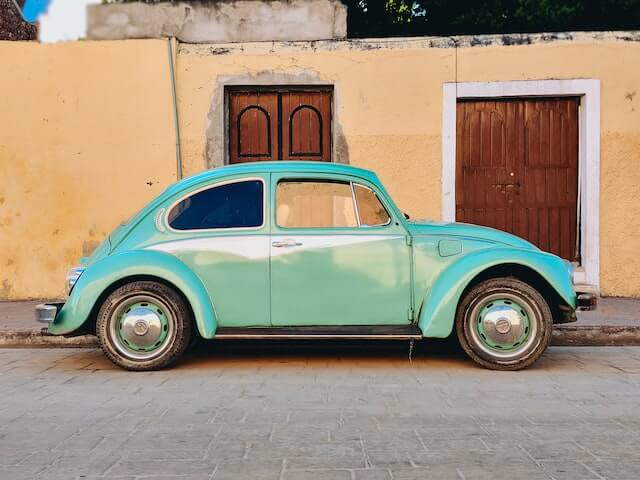

In [6]:
image

## Run pre-defined tasks without additional inputs

### Caption

In [7]:
task_prompt = '<CAPTION>'
run_example(task_prompt)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[   2,    0,  250, 2272,  512, 9181,   11,  760,    9,   10, 5718,  745,
            4,    2]], device='cuda:0')
generated_text ---> </s><s>A green car parked in front of a yellow building.</s>


{'<CAPTION>': 'A green car parked in front of a yellow building.'}

In [8]:
task_prompt = '<DETAILED_CAPTION>'
run_example(task_prompt)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[   2,    0, 1121,   42, 2274,    6,   52,   64,  192,   10,  512,   15,
            5,  921,    8,   11,    5, 3618,    6,   89,   32, 4259,    8,   52,
           64,   67,  192,   10, 2204,    4,  497,    5,  299,    6,   89,   16,
         6360,    4,    2]], device='cuda:0')
generated_text ---> </s><s>In this image, we can see a car on the road and in the background, there are doors and we can also see a wall. At the top, there is sky.</s>


{'<DETAILED_CAPTION>': 'In this image, we can see a car on the road and in the background, there are doors and we can also see a wall. At the top, there is sky.'}

In [9]:
task_prompt = '<MORE_DETAILED_CAPTION>'
run_example(task_prompt)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[   2,    0,  250, 1109, 2272,  512,   16, 9181,   11,  760,    9,   10,
         5718,  745,    4,  345,   16,   10, 6219, 1883,   15,    5,  745,  639,
            5,  512,    4, 1437,    2]], device='cuda:0')
generated_text ---> </s><s>A light green car is parked in front of a yellow building. There is a brown door on the building behind the car. </s>


{'<MORE_DETAILED_CAPTION>': 'A light green car is parked in front of a yellow building. There is a brown door on the building behind the car.'}

### Object detection

OD results format:
{'\<OD>':
    {
    'bboxes': [[x1, y1, x2, y2], ...],
    'labels': ['label1', 'label2', ...]
    }
}

In [10]:
task_prompt = '<OD>'
results = run_example(task_prompt)
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,  5901, 50323, 50603, 51202, 51043, 13630, 50977, 50845,
         51134, 51041, 50415, 50853, 50577, 51042,     2]], device='cuda:0')
generated_text ---> </s><s>car<loc_54><loc_334><loc_933><loc_774>wheel<loc_708><loc_576><loc_865><loc_772><loc_146><loc_584><loc_308><loc_773></s>
{'<OD>': {'bboxes': [[34, 160, 597, 371], [453, 276, 553, 370], [93, 280, 197, 371]], 'labels': ['car', 'wheel', 'wheel']}}


In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
def plot_bbox(image, data):
   # Create a figure and axes
    fig, ax = plt.subplots()

    # Display the image
    ax.imshow(image)

    # Plot each bounding box
    for bbox, label in zip(data['bboxes'], data['labels']):
        # Unpack the bounding box coordinates
        x1, y1, x2, y2 = bbox
        # Create a Rectangle patch
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=1, edgecolor='r', facecolor='none')
        # Add the rectangle to the Axes
        ax.add_patch(rect)
        # Annotate the label
        plt.text(x1, y1, label, color='white', fontsize=8, bbox=dict(facecolor='red', alpha=0.5))

    # Remove the axis ticks and labels
    ax.axis('off')

    # Show the plot
    plt.show()

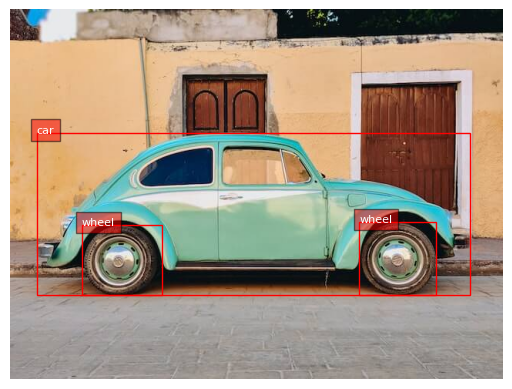

In [12]:
plot_bbox(image, results['<OD>'])

### Dense region caption

Dense region caption results format:
{'\<DENSE_REGION_CAPTION>': {'bboxes': [[x1, y1, x2, y2], ...], 'labels': ['label1', 'label2', ...]}}

In [13]:
task_prompt = '<DENSE_REGION_CAPTION>'
results = run_example(task_prompt)
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,  5901, 50323, 50603, 51202, 51043, 13630, 50978, 50845,
         51134, 51041, 50416, 50853, 50576, 51042,     2]], device='cuda:0')
generated_text ---> </s><s>car<loc_54><loc_334><loc_933><loc_774>wheel<loc_709><loc_576><loc_865><loc_772><loc_147><loc_584><loc_307><loc_773></s>
{'<DENSE_REGION_CAPTION>': {'bboxes': [[34, 160, 597, 371], [454, 276, 553, 370], [94, 280, 196, 371]], 'labels': ['car', 'wheel', 'wheel']}}


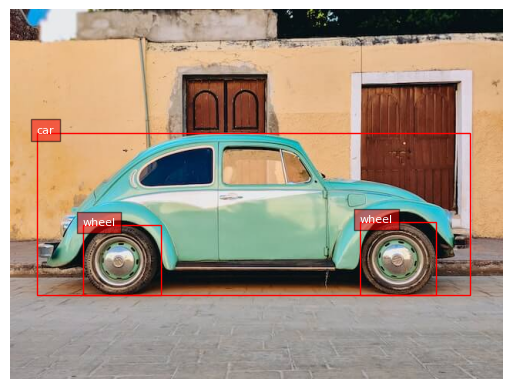

In [14]:
plot_bbox(image, results['<DENSE_REGION_CAPTION>'])

### Region proposal

Region proposal results format:
{'<REGION_PROPOSAL>' : {'bboxes': [[x1, y1, x2, y2], ...], 'labels': ['', '', ...]}}

In [15]:
task_prompt = '<REGION_PROPOSAL>'
results = run_example(task_prompt)
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

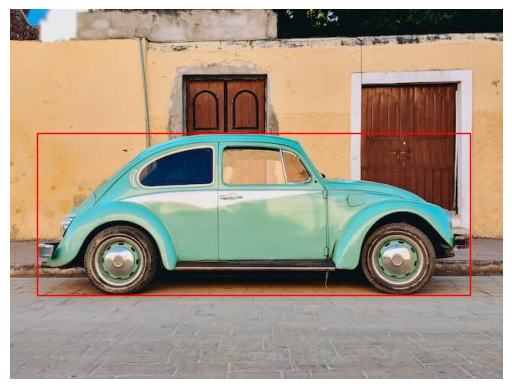

In [16]:
plot_bbox(image, results['<REGION_PROPOSAL>'])

## Run pre-defined tasks that requires additional inputs

### Phrase Grounding
Phrase grounding results format:
{'\<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[x1, y1, x2, y2], ...], 'labels': ['', '', ...]}}

In [17]:
task_prompt = '<CAPTION_TO_PHRASE_GROUNDING>'
results = run_example(task_prompt, text_input="A green car parked in front of a yellow building.")
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,   250,  2272,   512, 50324, 50600, 51180, 51050,   102,
          5718,   745, 50269, 50269, 51267, 50903,     2]], device='cuda:0')
generated_text ---> </s><s>A green car<loc_55><loc_331><loc_911><loc_781>a yellow building<loc_0><loc_0><loc_998><loc_634></s>
{'<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[35, 159, 583, 375], [0, 0, 639, 304]], 'labels': ['A green car', 'a yellow building']}}


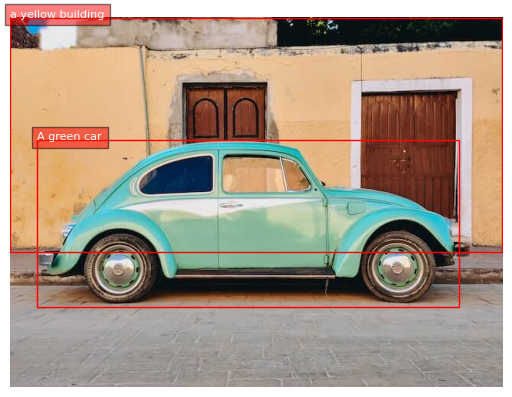

In [18]:
plot_bbox(image, results['<CAPTION_TO_PHRASE_GROUNDING>'])

### Referring expression segmentation

Referring expression segmentation results format:
{'\<REFERRING_EXPRESSION_SEGMENTATION>': {'Polygons': [[[polygon]], ...], 'labels': ['', '', ...]}}, one object is represented by a list of polygons. each polygon is [x1, y1, x2, y2, ..., xn, yn]

In [19]:
task_prompt = '<REFERRING_EXPRESSION_SEGMENTATION>'
results = run_example(task_prompt, text_input="a green car")
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0, 50557, 50639, 50691, 50604, 50850, 50620, 50911, 50730,
         51063, 50751, 51168, 50819, 51171, 50880, 51202, 50880, 51202, 50913,
         51171, 50920, 51171, 50941, 51135, 50946, 51124, 51009, 51096, 51042,
         51028, 51042, 50988, 51009, 50974, 50974, 50582, 50974, 50557, 51023,
         50515, 51042, 50459, 51042, 50423, 50995, 50412, 50962, 50343, 50969,
         50343, 50946, 50323, 50939, 50323, 50901, 50373, 50894, 50373, 50826,
         50398, 50826, 50398, 50805, 50472, 50723,     2]], device='cuda:0')
generated_text ---> </s><s><loc_288><loc_370><loc_422><loc_335><loc_581><loc_351><loc_642><loc_461><loc_794><loc_482><loc_899><loc_550><loc_902><loc_611><loc_933><loc_611><loc_933><loc_644><loc_902><loc_651><loc_902><loc_672><loc_866><loc_677><loc_855><loc_740><loc_827><loc_773><loc_759><loc_773><loc_719><loc_740><loc_705><loc_705><loc_313><loc_705><loc_288><loc_754><loc_246><loc_773><loc_190><loc_773><loc_154><loc_726><loc_14

In [20]:
from PIL import Image, ImageDraw, ImageFont
import random
import numpy as np
colormap = ['blue','orange','green','purple','brown','pink','gray','olive','cyan','red',
            'lime','indigo','violet','aqua','magenta','coral','gold','tan','skyblue']
def draw_polygons(image, prediction, fill_mask=False):
    """
    Draws segmentation masks with polygons on an image.

    Parameters:
    - image_path: Path to the image file.
    - prediction: Dictionary containing 'polygons' and 'labels' keys.
                  'polygons' is a list of lists, each containing vertices of a polygon.
                  'labels' is a list of labels corresponding to each polygon.
    - fill_mask: Boolean indicating whether to fill the polygons with color.
    """
    # Load the image

    draw = ImageDraw.Draw(image)


    # Set up scale factor if needed (use 1 if not scaling)
    scale = 1

    # Iterate over polygons and labels
    for polygons, label in zip(prediction['polygons'], prediction['labels']):
        color = random.choice(colormap)
        fill_color = random.choice(colormap) if fill_mask else None

        for _polygon in polygons:
            _polygon = np.array(_polygon).reshape(-1, 2)
            if len(_polygon) < 3:
                print('Invalid polygon:', _polygon)
                continue

            _polygon = (_polygon * scale).reshape(-1).tolist()

            # Draw the polygon
            if fill_mask:
                draw.polygon(_polygon, outline=color, fill=fill_color)
            else:
                draw.polygon(_polygon, outline=color)

            # Draw the label text
            draw.text((_polygon[0] + 8, _polygon[1] + 2), label, fill=color)

    # Save or display the image
    #image.show()  # Display the image
    display(image)

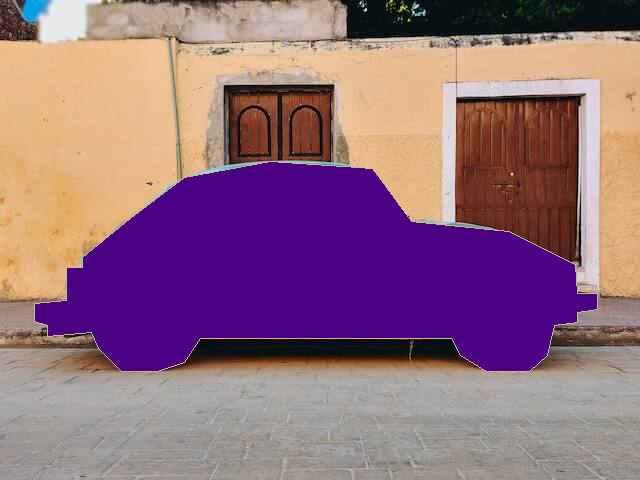

In [21]:
output_image = copy.deepcopy(image)
draw_polygons(output_image, results['<REFERRING_EXPRESSION_SEGMENTATION>'], fill_mask=True)

### region to segmentation


with additional region as inputs, format is '\<loc_x1>\<loc_y1>\<loc_x2>\<loc_y2>', [x1, y1, x2, y2] is the quantized coordinates in [0, 999].

In [22]:
task_prompt = '<REGION_TO_SEGMENTATION>'
results = run_example(task_prompt, text_input="<loc_702><loc_575><loc_866><loc_772>")
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0, 50996, 50872, 51027, 50849, 51062, 50844, 51096, 50859,
         51124, 50891, 51137, 50938, 51132, 50973, 51124, 51006, 51109, 51032,
         51081, 51043, 51043, 51043, 51014, 51032, 50996, 51013, 50985, 50985,
         50982, 50966, 50971, 50957, 50982, 50910,     2]], device='cuda:0')
generated_text ---> </s><s><loc_727><loc_603><loc_758><loc_580><loc_793><loc_575><loc_827><loc_590><loc_855><loc_622><loc_868><loc_669><loc_863><loc_704><loc_855><loc_737><loc_840><loc_763><loc_812><loc_774><loc_774><loc_774><loc_745><loc_763><loc_727><loc_744><loc_716><loc_716><loc_713><loc_697><loc_702><loc_688><loc_713><loc_641></s>
{'<REGION_TO_SEGMENTATION>': {'polygons': [[[465, 289, 485, 278, 507, 276, 529, 283, 547, 298, 555, 321, 552, 338, 547, 354, 537, 366, 520, 371, 495, 371, 477, 366, 465, 357, 458, 343, 456, 334, 449, 330, 456, 307]]], 'labels': ['']}}


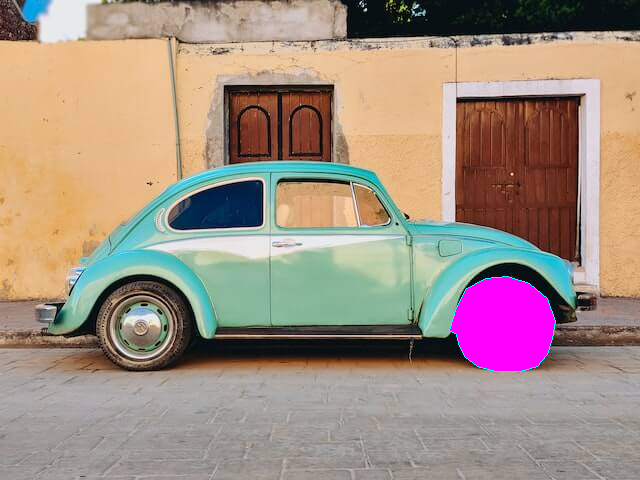

In [23]:
output_image = copy.deepcopy(image)
draw_polygons(output_image, results['<REGION_TO_SEGMENTATION>'], fill_mask=True)

### Open vocabulary detection

open vocabulary detection can detect both objects and ocr texts.

results format:

{ '\<OPEN_VOCABULARY_DETECTION>': {'bboxes': [[x1, y1, x2, y2], [x1, y1, x2, y2], ...]], 'bboxes_labels': ['label_1', 'label_2', ..],
'polygons': [[[x1, y1, x2, y2, ..., xn, yn], [x1, y1, ..., xn, yn]], ...], 'polygons_labels': ['label_1', 'label_2', ...]
}}

In [24]:
task_prompt = '<OPEN_VOCABULARY_DETECTION>'
results = run_example(task_prompt, text_input="a green car")
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,   102,  2272,   512, 50323, 50600, 51179, 51049,     2]],
       device='cuda:0')
generated_text ---> </s><s>a green car<loc_54><loc_331><loc_910><loc_780></s>
{'<OPEN_VOCABULARY_DETECTION>': {'bboxes': [[34, 159, 582, 374]], 'bboxes_labels': ['a green car'], 'polygons': [], 'polygons_labels': []}}


In [25]:
def convert_to_od_format(data):
    """
    Converts a dictionary with 'bboxes' and 'bboxes_labels' into a dictionary with separate 'bboxes' and 'labels' keys.

    Parameters:
    - data: The input dictionary with 'bboxes', 'bboxes_labels', 'polygons', and 'polygons_labels' keys.

    Returns:
    - A dictionary with 'bboxes' and 'labels' keys formatted for object detection results.
    """
    # Extract bounding boxes and labels
    bboxes = data.get('bboxes', [])
    labels = data.get('bboxes_labels', [])

    # Construct the output format
    od_results = {
        'bboxes': bboxes,
        'labels': labels
    }

    return od_results

In [26]:
bbox_results  = convert_to_od_format(results['<OPEN_VOCABULARY_DETECTION>'])

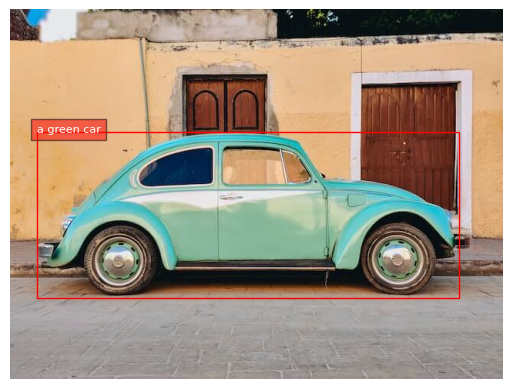

In [27]:
plot_bbox(image, bbox_results)

### region to texts

In [28]:
task_prompt = '<REGION_TO_CATEGORY>'
results = run_example(task_prompt, text_input="<loc_52><loc_332><loc_932><loc_774>")
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,  5901, 50321, 50601, 51201, 51043,     2]],
       device='cuda:0')


generated_text ---> </s><s>car<loc_52><loc_332><loc_932><loc_774></s>
{'<REGION_TO_CATEGORY>': 'car<loc_52><loc_332><loc_932><loc_774>'}


In [29]:
task_prompt = '<REGION_TO_DESCRIPTION>'
results = run_example(task_prompt, text_input="<loc_52><loc_332><loc_932><loc_774>")
print(results)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,  5901, 50321, 50601, 51201, 51043,     2]],
       device='cuda:0')
generated_text ---> </s><s>car<loc_52><loc_332><loc_932><loc_774></s>
{'<REGION_TO_DESCRIPTION>': 'car<loc_52><loc_332><loc_932><loc_774>'}


## ocr related tasks

In [30]:
url = "http://ecx.images-amazon.com/images/I/51UUzBDAMsL.jpg?download=true"
image = Image.open(requests.get(url, stream=True).raw).convert('RGB')

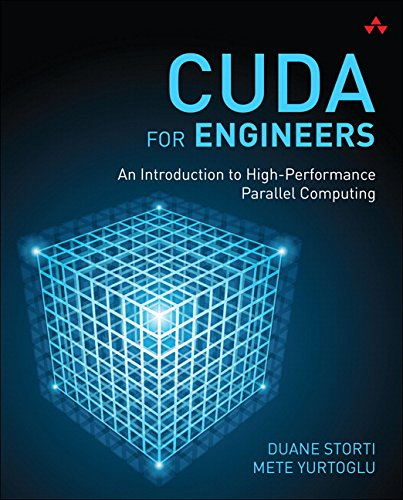

In [31]:
image

In [32]:
task_prompt = '<OCR>'
run_example(task_prompt)

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,   347, 13083,  8573,  3411, 40565, 13974,  4322,  4688,
         24474,     7,   755,    12, 44002, 22011, 44682, 34572,   495,   791,
         19621, 28365,  3755,  3935,   717,   854,  2492,   565, 10207, 39826,
             2]], device='cuda:0')
generated_text ---> </s><s>CUDAFOR ENGINEERSAn Introduction to High-PerformanceParallel ComputingDUANE STORYIMETE YURTOGLU</s>


{'<OCR>': 'CUDAFOR ENGINEERSAn Introduction to High-PerformanceParallel ComputingDUANE STORYIMETE YURTOGLU'}

In [33]:
task_prompt = '<OCR_WITH_REGION>'
results = run_example(task_prompt)
print(results)
# ocr results format
# {'OCR_WITH_REGION': {'quad_boxes': [[x1, y1, x2, y2, x3, y3, x4, y4], ...], 'labels': ['text1', ...]}}

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[    2,     0,   347, 13083,   250, 50685, 50369, 51198, 50369, 51198,
         50497, 50685, 50497, 27201, 40565, 13974,  4322, 50628, 50511, 51198,
         50509, 51198, 50566, 50628, 50568,  4688, 24474,     7,   755,    12,
         44002, 50556, 50600, 51203, 50600, 51203, 50637, 50556, 50635, 22011,
         44682, 34572, 50864, 50639, 51203, 50641, 51203, 50677, 50864, 50673,
           495,   791, 19621, 17399, 13216, 50929, 51151, 51201, 51151, 51201,
         51181, 50929, 51181, 43543,   717,   854,  2492,   565, 10207, 39826,
         50892, 51188, 51201, 51188, 51201, 51218, 50892, 51218,     2]],
       device='cuda:0')
generated_text ---> </s><s>CUDA<loc_416><loc_100><loc_929><loc_100><loc_929><loc_228><loc_416><loc_228>FOR ENGINEERS<loc_359><loc_242><loc_929><loc_240><loc_929><loc_297><loc_359><loc_299>An Introduction to High-Performance<loc_287><loc_331><loc_934><loc_331><loc_934><loc_368><loc_287><loc_366>Parallel Computing<loc_595><loc_370

In [34]:
def draw_ocr_bboxes(image, prediction):
    scale = 1
    draw = ImageDraw.Draw(image)
    bboxes, labels = prediction['quad_boxes'], prediction['labels']
    for box, label in zip(bboxes, labels):
        color = random.choice(colormap)
        new_box = (np.array(box) * scale).tolist()
        draw.polygon(new_box, width=3, outline=color)
        draw.text((new_box[0]+8, new_box[1]+2),
                    "{}".format(label),
                    align="right",

                    fill=color)
    display(image)


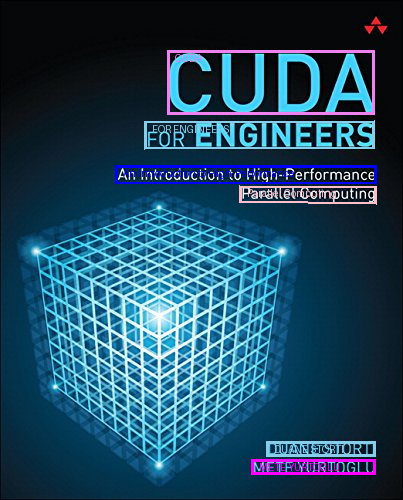

In [35]:
output_image = copy.deepcopy(image)
draw_ocr_bboxes(output_image, results['<OCR_WITH_REGION>'])

## Cascaded tasks

### Caption + Phrase Grounding

results format:

{
 '\<CAPTION': pure_text,
{'\<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[x1, y1, x2, y2], ...], 'labels': ['', '', ...]}}
}

In [36]:
url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/car.jpg?download=true"
image = Image.open(requests.get(url, stream=True).raw)

In [37]:
task_prompt = '<CAPTION>'
results = run_example(task_prompt)
text_input = results[task_prompt]
task_prompt = '<CAPTION_TO_PHRASE_GROUNDING>'
results = run_example(task_prompt, text_input)
results['<CAPTION>'] = text_input

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[   2,    0,  250, 2272,  512, 9181,   11,  760,    9,   10, 5718,  745,
            4,    2]], device='cuda:0')
generated_text ---> </s><s>A green car parked in front of a yellow building.</s>
inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289

generated_ids ---> tensor([[    2,     0,   250,  2272,   512, 50324, 50600, 51180, 51050,   102,
          5718,   745, 50269, 50269, 51267, 50903,     2]], device='cuda:0')
generated_text ---> </s><s>A green car<loc_55><loc_331><loc_911><loc_781>a yellow building<loc_0><loc_0><loc_998><loc_634></s>


In [38]:
results

{'<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[35, 159, 583, 375],
   [0, 0, 639, 304]],
  'labels': ['A green car', 'a yellow building']},
 '<CAPTION>': 'A green car parked in front of a yellow building.'}

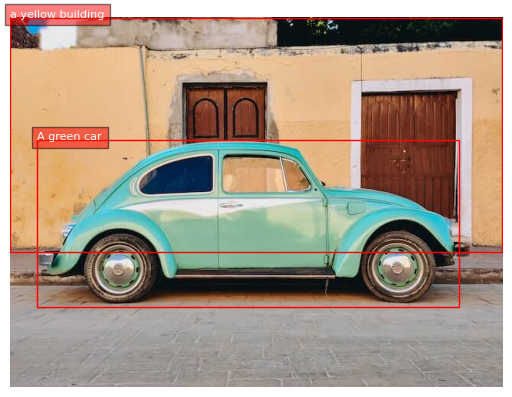

In [39]:
plot_bbox(image, results['<CAPTION_TO_PHRASE_GROUNDING>'])

### Detailed Caption + Phrase Grounding

results format:

{
 '\<DETAILED_CAPTION': pure_text,
{'\<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[x1, y1, x2, y2], ...], 'labels': ['', '', ...]}}
}

In [40]:
task_prompt = '<DETAILED_CAPTION>'
results = run_example(task_prompt)
text_input = results[task_prompt]
task_prompt = '<CAPTION_TO_PHRASE_GROUNDING>'
results = run_example(task_prompt, text_input)
results['<DETAILED_CAPTION>'] = text_input

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[   2,    0, 1121,   42, 2274,    6,   52,   64,  192,   10,  512,   15,
            5,  921,    8,   11,    5, 3618,    6,   89,   32, 4259,    8,   52,
           64,   67,  192,   10, 2204,    4,  497,    5,  299,    6,   89,   16,
         6360,    4,    2]], device='cuda:0')
generated_text ---> </s><s>In this image, we can see a car on the road and in the background, there are doors and we can also see a wall. At the top, there is sky.</s>
inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 5

generated_ids ---> tensor([[    2,     0,   102,   512, 50322, 50600, 51180, 51050,   627,   921,
         50269, 50980, 51267, 51267, 31618, 50977, 50464, 51179, 50824, 50617,
         50444, 50793, 50618,   102,  2204, 50269, 50269, 51267, 50901, 50269,
         50337, 51267, 50899,   627,   299, 50269, 50269, 51266, 50361, 18708,
         50269, 50269, 51265, 50361,     2]], device='cuda:0')
generated_text ---> </s><s>a car<loc_53><loc_331><loc_911><loc_781>the road<loc_0><loc_711><loc_998><loc_998>doors<loc_708><loc_195><loc_910><loc_555><loc_348><loc_175><loc_524><loc_349>a wall<loc_0><loc_0><loc_998><loc_632><loc_0><loc_68><loc_998><loc_630>the top<loc_0><loc_0><loc_997><loc_92>sky<loc_0><loc_0><loc_996><loc_92></s>


In [41]:
results

{'<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[34, 159, 583, 375],
   [0, 341, 639, 479],
   [453, 93, 582, 266],
   [223, 84, 335, 167],
   [0, 0, 639, 303],
   [0, 32, 639, 302],
   [0, 0, 638, 44],
   [0, 0, 637, 44]],
  'labels': ['a car',
   'the road',
   'doors',
   'doors',
   'a wall',
   'a wall',
   'the top',
   'sky']},
 '<DETAILED_CAPTION>': 'In this image, we can see a car on the road and in the background, there are doors and we can also see a wall. At the top, there is sky.'}

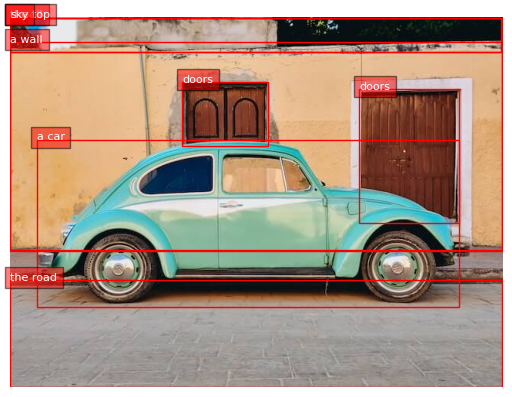

In [42]:
plot_bbox(image, results['<CAPTION_TO_PHRASE_GROUNDING>'])

### More Detailed Caption + Phrase Grounding

results format:

{
 '\<MORE_DETAILED_CAPTION': pure_text,
{'\<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[x1, y1, x2, y2], ...], 'labels': ['', '', ...]}}
}

In [43]:
task_prompt = '<MORE_DETAILED_CAPTION>'
results = run_example(task_prompt)
text_input = results[task_prompt]
task_prompt = '<CAPTION_TO_PHRASE_GROUNDING>'
results = run_example(task_prompt, text_input)
results['<MORE_DETAILED_CAPTION>'] = text_input

inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 512

generated_ids ---> tensor([[   2,    0,  250, 1109, 2272,  512,   16, 9181,   11,  760,    9,   10,
         5718,  745,    4,  345,   16,   10, 6219, 1883,   15,    5,  745,  639,
            5,  512,    4, 1437,    2]], device='cuda:0')
generated_text ---> </s><s>A light green car is parked in front of a yellow building. There is a brown door on the building behind the car. </s>
inputs ---> {'input_ids': tensor([[51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289, 51289,
         51289, 51289, 51289, 51289, 

generated_ids ---> tensor([[    2,     0,   250,  1109,  2272,   512, 50324, 50599, 51180, 51049,
           102,  5718,   745, 50269, 50269, 51267, 50902,   102,  6219,  1883,
         50979, 50465, 51179, 50822,   627,   745, 50269, 50270, 51267, 50902,
           627,   512, 50324, 50600, 51180, 51049,     2]], device='cuda:0')
generated_text ---> </s><s>A light green car<loc_55><loc_330><loc_911><loc_780>a yellow building<loc_0><loc_0><loc_998><loc_633>a brown door<loc_710><loc_196><loc_910><loc_553>the building<loc_0><loc_1><loc_998><loc_633>the car<loc_55><loc_331><loc_911><loc_780></s>


In [44]:
results

{'<CAPTION_TO_PHRASE_GROUNDING>': {'bboxes': [[35, 158, 583, 374],
   [0, 0, 639, 304],
   [454, 94, 582, 265],
   [0, 0, 639, 304],
   [35, 159, 583, 374]],
  'labels': ['A light green car',
   'a yellow building',
   'a brown door',
   'the building',
   'the car']},
 '<MORE_DETAILED_CAPTION>': 'A light green car is parked in front of a yellow building. There is a brown door on the building behind the car.'}

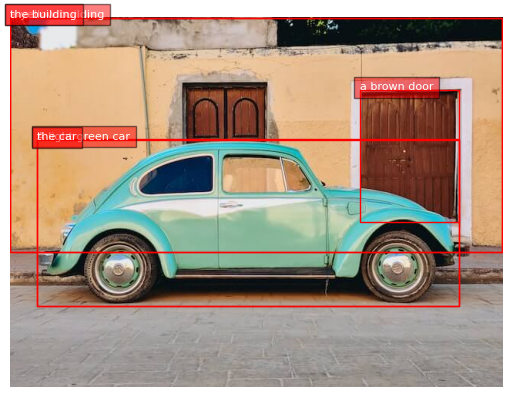

In [45]:
plot_bbox(image, results['<CAPTION_TO_PHRASE_GROUNDING>'])